# A Time Ordered Public Return Experiment

This native Julia companion preserves the public formulas, finite vertex order, inputs and original seeds. Julia computes the oracle decisions, losses and gradients; Zygote supplies the native counterpart of the Python tensor adapter. Vertex indices in displayed tables retain the original zero-based convention. Julia ArgumentError corresponds to Python ValueError for invalid inputs. Figures use the requested dark theme and outputs are saved under `outputs/julia`.

## Enforcing the information boundary in public data

For industry $i$ and decision date $t$, the feature vector is

$$
x_{i,t}
=
\left(
1,
\overline r_{i,t}^{(5)},
\overline r_{i,t}^{(20)},
\overline r_{i,t}^{(60)},
s_{i,t}^{(5)},
s_{i,t}^{(20)},
s_{i,t}^{(60)}
\right)^{\mathsf T}.
$$

Here, $\overline r_{i,t}^{(h)}$ and $s_{i,t}^{(h)}$ are the mean and sample standard deviation of the previous $h$ daily percentage returns. Every window ends on the day before $t$. The leading one is an intercept. Standardization uses the training period only.

### The Supplied Portfolio Vertices

Each feasible decision holds exactly four of the sixteen industries with equal weights:

$$
V
=
\left\{
w\in\{0,1/4\}^{16}:
\sum_{i=1}^{16}w_i=1
\right\}.
$$

The set contains $\binom{16}{4}=1{,}820$ vertices. The observed daily cost vector is $c_t=-r_t$, so minimizing cost is the same as maximizing the next observed portfolio return. This is a finite teaching experiment, not a trading recommendation.

4,Industries retained,16
5,Download during execution,None
6,Simulated observations,None


Row,Period,Start,End,Raw observations,Usable decisions
,String,String,String,Int64,Int64
1,Training,2019-01-01,2021-12-31,757,697
2,Validation,2022-01-01,2023-12-31,501,501
3,Final test,2024-01-01,2025-12-31,502,502


Row,Feature,Window,Latest permitted input,Training standardization only
,String,Int64,String,String
1,Past 5-day mean,5,Day before decision,Pass
2,Past 20-day mean,20,Day before decision,Pass
3,Past 60-day mean,60,Day before decision,Pass
4,Past 5-day volatility,5,Day before decision,Pass
5,Past 20-day volatility,20,Day before decision,Pass
6,Past 60-day volatility,60,Day before decision,Pass


Row,Window,First target date,Earliest input date,Latest input date,Latest input precedes target
,Int64,String,String,String,String
1,5,2019-03-29,2019-03-22,2019-03-28,Pass
2,20,2019-03-29,2019-03-01,2019-03-28,Pass
3,60,2019-03-29,2019-01-02,2019-03-28,Pass


Row,Quantity,Value,Check
,String,Float64,String
1,Assets,16.0,Pass
2,Assets held per vertex,4.0,Pass
3,Weight per selected asset,0.25,Pass
4,Enumerated vertices,1820.0,Pass
5,Smallest vertex total,1.0,Pass
6,Largest vertex total,1.0,Pass


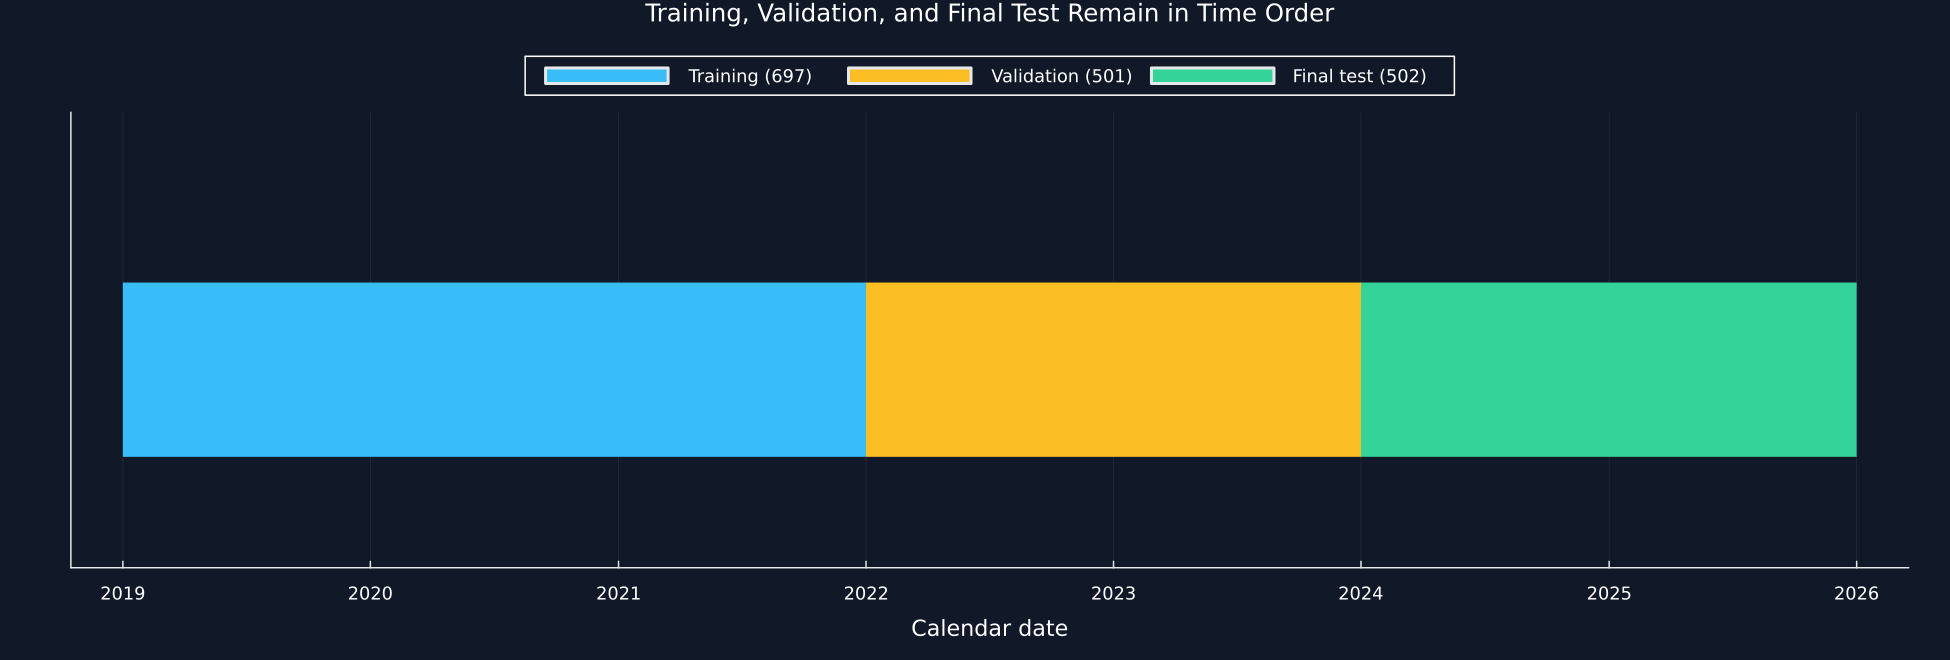

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"0.6.2"
configure_plots!()
paths = output_paths("27_decision_focused_learning");
using CSV, TOML, Printf, Zygote, Combinatorics
using RiskLabAI.Optimization: spo_plus_loss,spo_plus,robust_mean_variance
default(left_margin=10Plots.mm,bottom_margin=8Plots.mm)
violet = "#C084FC"
function table(frame,name,caption)
    shown = copy(frame)
    for column in names(shown)
        if eltype(shown[!,column])<:Bool
            shown[!,column] = ifelse.(shown[!,column],"Pass","Fail")
        end
    end
    save_table(shown,paths,name;caption,label="tab:chapter28-"*replace(name,"_"=>"-"))
    return nothing
end
random_root = joinpath("..","data","chapter27_random_inputs")
random_manifest = TOML.parsefile(joinpath(random_root,"inputs.toml"))["files"]
function primitive(name)
    path = joinpath(random_root,name)
    return Matrix{Float64}(CSV.read(path,DataFrame))
end
include(joinpath("..","support","BookDecisionStudy.jl"))
using .BookDecisionStudy
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
lines = readlines(data_path)
first_row = findfirst(line->startswith(line,",Agric"),lines)
last_row = findnext(line->isempty(strip(line)),lines,first_row+1)
raw = CSV.read(IOBuffer(join(lines[],"\n")),DataFrame)
all_dates = Date.(string.(raw[!,1]),dateformat"yyyymmdd")
all_values = Matrix{Float64}(raw[:,2:17])
valid = (Date(2019,1,1).<=all_dates).&(all_dates.<=Date(2025,12,31)).&vec(all(all_values.>-99;dims=2))
public_dates,public_values = all_dates[valid],all_values[valid,:]
industries = names(raw)[2:17]
@assert length(industries)==16
@assert length(public_dates)==1760
study = decision_design(public_values,public_dates)
dates,vertices,members = study.dates,study.vertices,study.members
train_mask = dates.<=Date(2021,12,31)
validation_mask = (Date(2022,1,1).<=dates).&(dates.<=Date(2023,12,31))
test_mask = dates.>=Date(2024,1,1)
feature_names = ["Past "*string(window)*"-day "*kind for kind in ["mean","volatility"] for window in [5,20,60]]
@assert length(members)==1820
@assert vec(sum(vertices;dims=2))≈ones(1820)
provenance = DataFrame("Item"=>["Public source","Stored archive","Industries retained","Download during execution","Simulated observations"],"Value"=>["Kenneth R. French Data Library, 49 Industry Portfolios Daily","49_Industry_Portfolios_daily_CSV.zip","16","None","None"])
table(provenance,"decision_public_data_provenance","Public data provenance for the decision experiment.")
periods = [("Training",Date(2019,1,1),Date(2021,12,31)),("Validation",Date(2022,1,1),Date(2023,12,31)),("Final test",Date(2024,1,1),Date(2025,12,31))]
period_table = DataFrame([(Period=name,Start=string(start),End=string(stop),raw=count(start.<=public_dates.<=stop),usable=count(start.<=dates.<=stop)) for (name,start,stop) in periods])
rename!(period_table,["Period","Start","End","Raw observations","Usable decisions"])
@assert period_table[!,"Raw observations"]==[757,501,502]
table(period_table,"decision_chronological_periods","Fixed chronological periods before and after feature losses.")
feature_table = DataFrame("Feature"=>feature_names,"Window"=>[5,20,60,5,20,60],"Latest permitted input"=>fill("Day before decision",6),"Training standardization only"=>trues(6))
table(feature_table,"decision_feature_definitions","Past-return features used by both linear rules.")
timing_table = DataFrame("Window"=>[5,20,60],"First target date"=>fill(string(first(dates)),3),"Earliest input date"=>string.([public_dates[61-window] for window in [5,20,60]]),"Latest input date"=>fill(string(public_dates[60]),3),"Latest input precedes target"=>fill(public_dates[60]<first(dates),3))
@assert all(timing_table[!,"Latest input precedes target"])
table(timing_table,"decision_feature_timing_checks","Direct checks that every first feature window ends before its target.")
feasible_summary = DataFrame("Quantity"=>["Assets","Assets held per vertex","Weight per selected asset","Enumerated vertices","Smallest vertex total","Largest vertex total"],"Value"=>[16,4,0.25,1820,minimum(sum(vertices;dims=2)),maximum(sum(vertices;dims=2))],"Check"=>trues(6))
table(feasible_summary,"decision_feasible_set_summary","Checks for the supplied four-industry portfolio vertices.")
save_data(period_table,paths,"decision_timeline")
figure = plot(;title="Training, Validation, and Final Test Remain in Time Order",xlabel="Calendar date",yticks=false,ylim=(-0.5,0.65),legend=:outertop,legend_columns=3,size=(1300,440))
for (index,((name,start,stop),color)) in enumerate(zip(periods,[palette.cyan,palette.amber,palette.green]))
    plot!(figure,Shape([Dates.value(start),Dates.value(stop+Day(1)),Dates.value(stop+Day(1)),Dates.value(start)],[-0.22,-0.22,0.22,0.22]);color,linealpha=0,label=name*" ("*string(period_table[index,"Usable decisions"])*")")
end
ticks = Date.(2019:2026,1,1)
plot!(figure;xticks=(Dates.value.(ticks),string.(year.(ticks))))
save_figure(figure,paths,"decision_timeline")
save_data(DataFrame(study.features,:auto),paths,"native_features")
save_data(DataFrame(study.design,:auto),paths,"native_design")
nothing


## Two Linear Prediction Rules with the Same Size

Both rules use the same shared coefficient vector $\beta\in\mathbb R^{7}$:

$$
\widehat c_{i,t}=x_{i,t}^{\mathsf T}\beta.
$$

The first rule minimizes the average squared error over sampled industry costs. The second minimizes the average SPO+ loss over sampled dates. Both start at zero, use the same eighty update steps, the same batch size, and the same learning rate. Only the training loss changes. Validation and final test observations never update either rule.

Row,Setting,Value
,String,String
1,Shared coefficients per rule,7
2,Update steps,80
3,Batch size,32
4,Learning rate,0.02
5,Random seed,2802
6,Feasible vertices,1820
7,Final test used in training,No


Row,Rule,First loss,Last loss,Smallest saved loss
,String,Float64,Float64,Float64
1,SPO+,2.31578,2.35561,2.12289
2,Squared error,1.66682,5.42388,1.38654


Row,Feature,Squared error coefficient,SPO+ coefficient
,String,Float64,Float64
1,Intercept,-0.0397743,0.0
2,Past 5-day mean,-0.0885506,0.10558
3,Past 20-day mean,0.0449456,0.028659
4,Past 60-day mean,0.0688355,0.0150839
5,Past 5-day volatility,0.158182,-0.0415788
6,Past 20-day volatility,-0.0204648,0.0139278
7,Past 60-day volatility,-0.0881262,-0.0441328


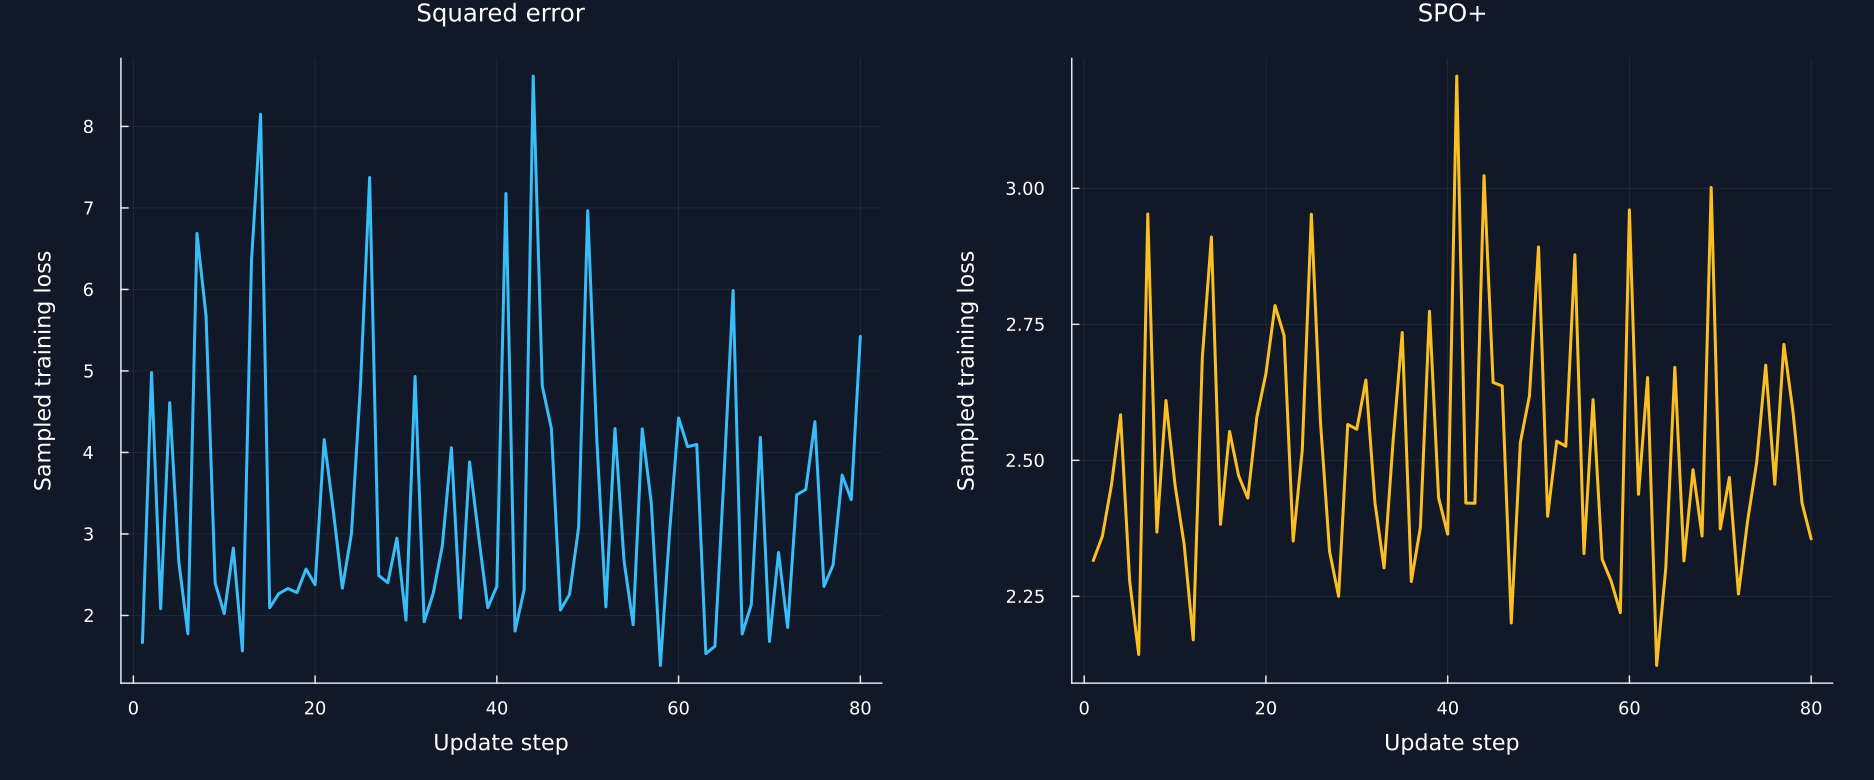

In [2]:
training_trace = NamedTuple[]
function training_recorder(name)
    return (step,loss,gradient,beta,prediction,truth)->append!(training_trace,[(rule=name,step=step,component=i,beta=beta[i],gradient=gradient[i]) for i in 1:7])
end
batches = primitive("training_batches.csv")
fitted_mse = train_decision_rule(study.design,study.costs,vertices,batches,"Squared error";trace=training_recorder("Squared error"))
fitted_spo = train_decision_rule(study.design,study.costs,vertices,batches,"SPO+";trace=training_recorder("SPO+"))
beta_mse,beta_spo = fitted_mse.beta,fitted_spo.beta
@assert all(isfinite,beta_mse)&&all(isfinite,beta_spo)
history = vcat(DataFrame("Iteration"=>1:80,"Rule"=>fill("Squared error",80),"Training loss"=>fitted_mse.history),DataFrame("Iteration"=>1:80,"Rule"=>fill("SPO+",80),"Training loss"=>fitted_spo.history))
settings = DataFrame("Setting"=>["Shared coefficients per rule","Update steps","Batch size","Learning rate","Random seed","Feasible vertices","Final test used in training"],"Value"=>["7","80","32","0.02","2802","1820","No"])
table(settings,"decision_training_settings","Fixed settings shared by the two linear training runs.")
loss_summary = combine(groupby(history,:Rule;sort=true),"Training loss"=>first=>"First loss","Training loss"=>last=>"Last loss","Training loss"=>minimum=>"Smallest saved loss")
table(loss_summary,"decision_training_loss_summary","Saved training loss summaries for the two rules.")
parameters = DataFrame("Feature"=>vcat("Intercept",feature_names),"Squared error coefficient"=>beta_mse,"SPO+ coefficient"=>beta_spo)
table(parameters,"decision_linear_coefficients","Shared linear coefficients after the fixed training runs.")
save_data(history,paths,"decision_training_losses")
panels = [plot(1:80,fit.history;color,title=name,xlabel="Update step",ylabel="Sampled training loss",legend=false) for (name,fit,color) in [("Squared error",fitted_mse,palette.cyan),("SPO+",fitted_spo,palette.amber)]]
save_figure(plot(panels...;layout=(1,2),size=(1250,520)),paths,"decision_training_losses")
save_data(DataFrame(training_trace),paths,"native_training_parameters")
nothing


## Chronological Evaluation

For a rule $m$ on date $t$, let $\widehat w_{m,t}=w^{*}(\widehat c_{m,t})$. Its observed regret is

$$
R_{m,t}
=
c_t^{\mathsf T}\widehat w_{m,t}
-
c_t^{\mathsf T}w^{*}(c_t).
$$

Here, $R_{m,t}$ compares the selected vertex with the best supplied vertex after the next return is observed. It is nonnegative by construction. Turnover is one half of the sum of absolute weight changes between successive selected vertices. These are descriptive results for the declared split.

Row,Period,Rule,Mean squared error,Mean decision regret,Mean selected cost,Mean best vertex cost,Exact decision share,Mean turnover
,String,String,Float64,Float64,Float64,Float64,Float64,Float64
1,Validation,Squared error,2.50898,1.20907,0.0347505,-1.17432,0.00399202,0.282
2,Validation,SPO+,2.51045,1.18215,0.00782934,-1.17432,0.00598802,0.257


Row,Period,Rule,Mean squared error,Mean decision regret,Mean selected cost,Mean best vertex cost,Exact decision share,Mean turnover
,String,String,Float64,Float64,Float64,Float64,Float64,Float64
1,Final test,Squared error,1.84861,1.08553,-0.0780129,-1.16355,0.0,0.283433
2,Final test,SPO+,1.84427,1.11322,-0.0503287,-1.16355,0.0059761,0.279441


Row,Decision,Mean observed cost,Mean turnover,Inside four-industry feasible set
,String,Float64,Float64,String
1,Equal weight over sixteen industries,-0.0326519,0.0,Fail
2,Squared error selected vertices,-0.0780129,0.283433,Pass
3,SPO+ selected vertices,-0.0503287,0.279441,Pass


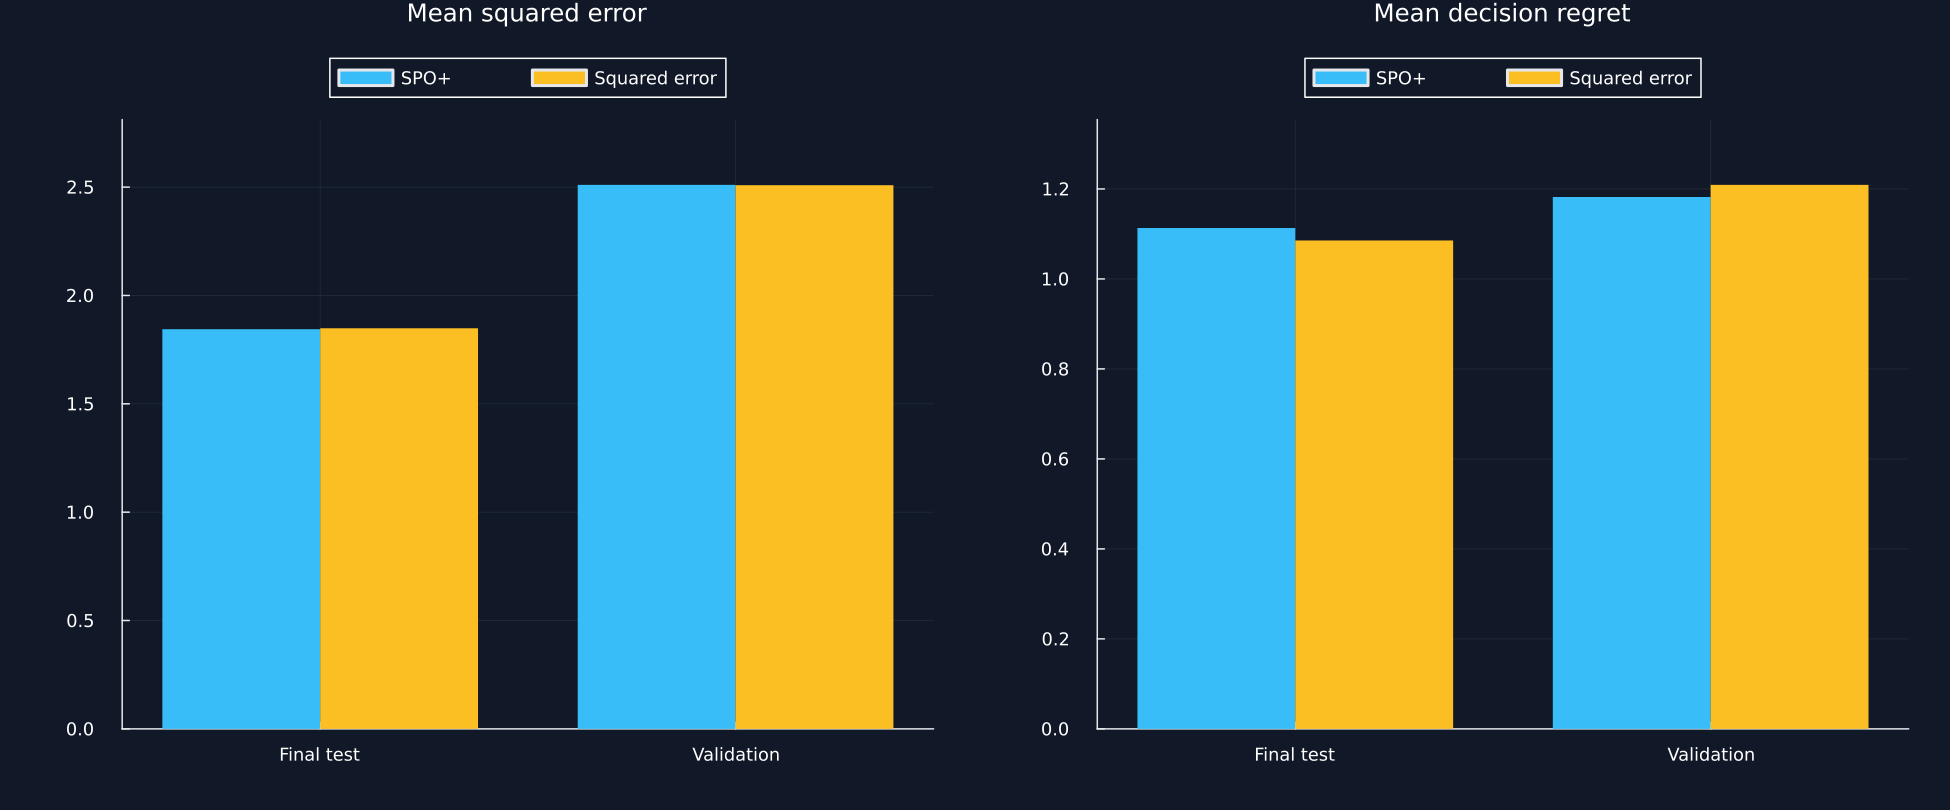

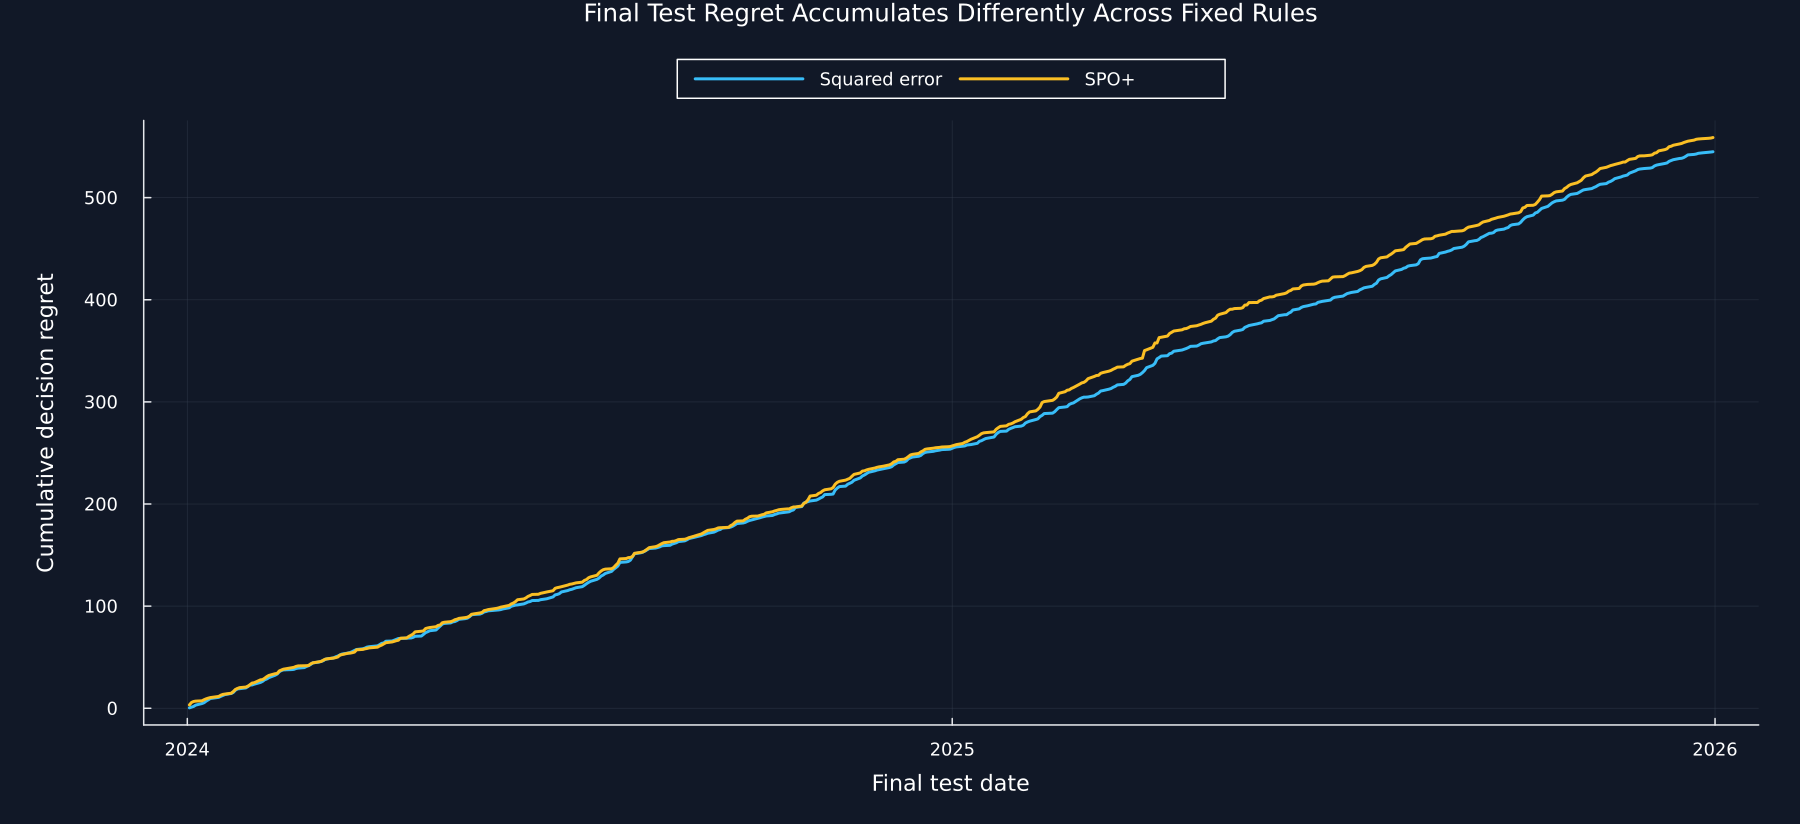

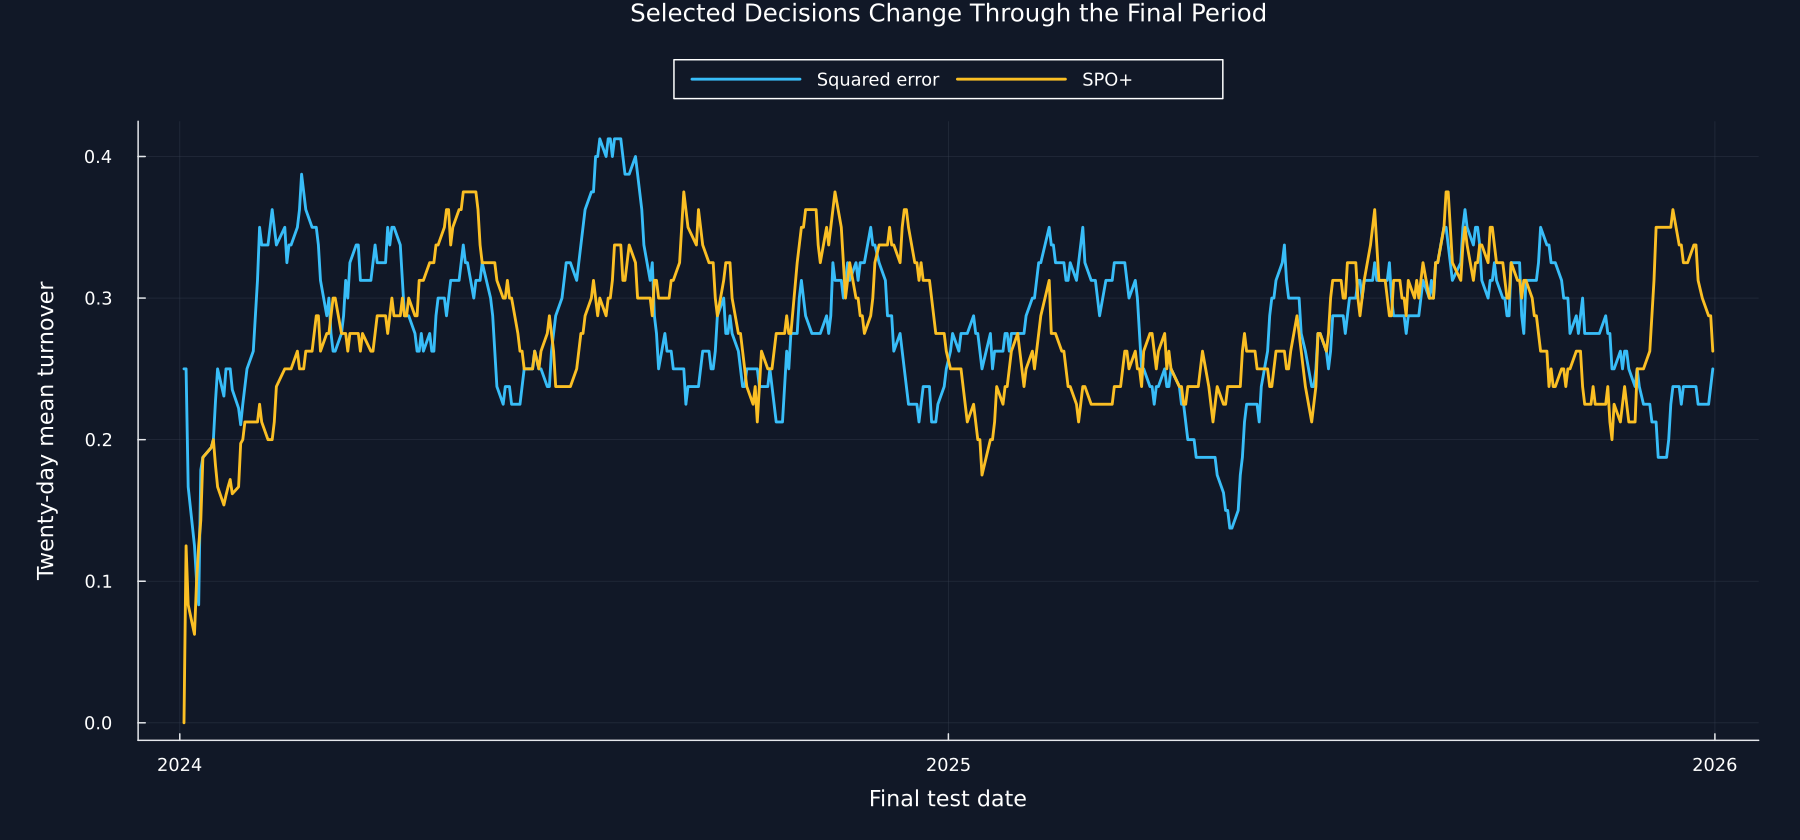

Row,Industry,Rule,Selection share
,String,String,Float64
1,Agric,Squared error,0.312749
2,Food,Squared error,0.2749
3,Soda,Squared error,0.13745
4,Beer,Squared error,0.326693
5,Smoke,Squared error,0.203187
6,Toys,Squared error,0.258964
7,Fun,Squared error,0.183267
8,Books,Squared error,0.268924
9,Hshld,Squared error,0.258964


Row,Industry,Rule,Selection share
,String,String,Float64
1,Agric,Squared error,0.312749
2,Food,Squared error,0.2749
3,Soda,Squared error,0.13745
4,Beer,Squared error,0.326693
5,Smoke,Squared error,0.203187
6,Toys,Squared error,0.258964
7,Fun,Squared error,0.183267
8,Books,Squared error,0.268924
9,Hshld,Squared error,0.258964


Row,Industry,Rule,Selection share
,String,String,Float64
1,Agric,SPO+,0.262948
2,Food,SPO+,0.171315
3,Soda,SPO+,0.103586
4,Beer,SPO+,0.312749
5,Smoke,SPO+,0.239044
6,Toys,SPO+,0.342629
7,Fun,SPO+,0.256972
8,Books,SPO+,0.175299
9,Hshld,SPO+,0.145418


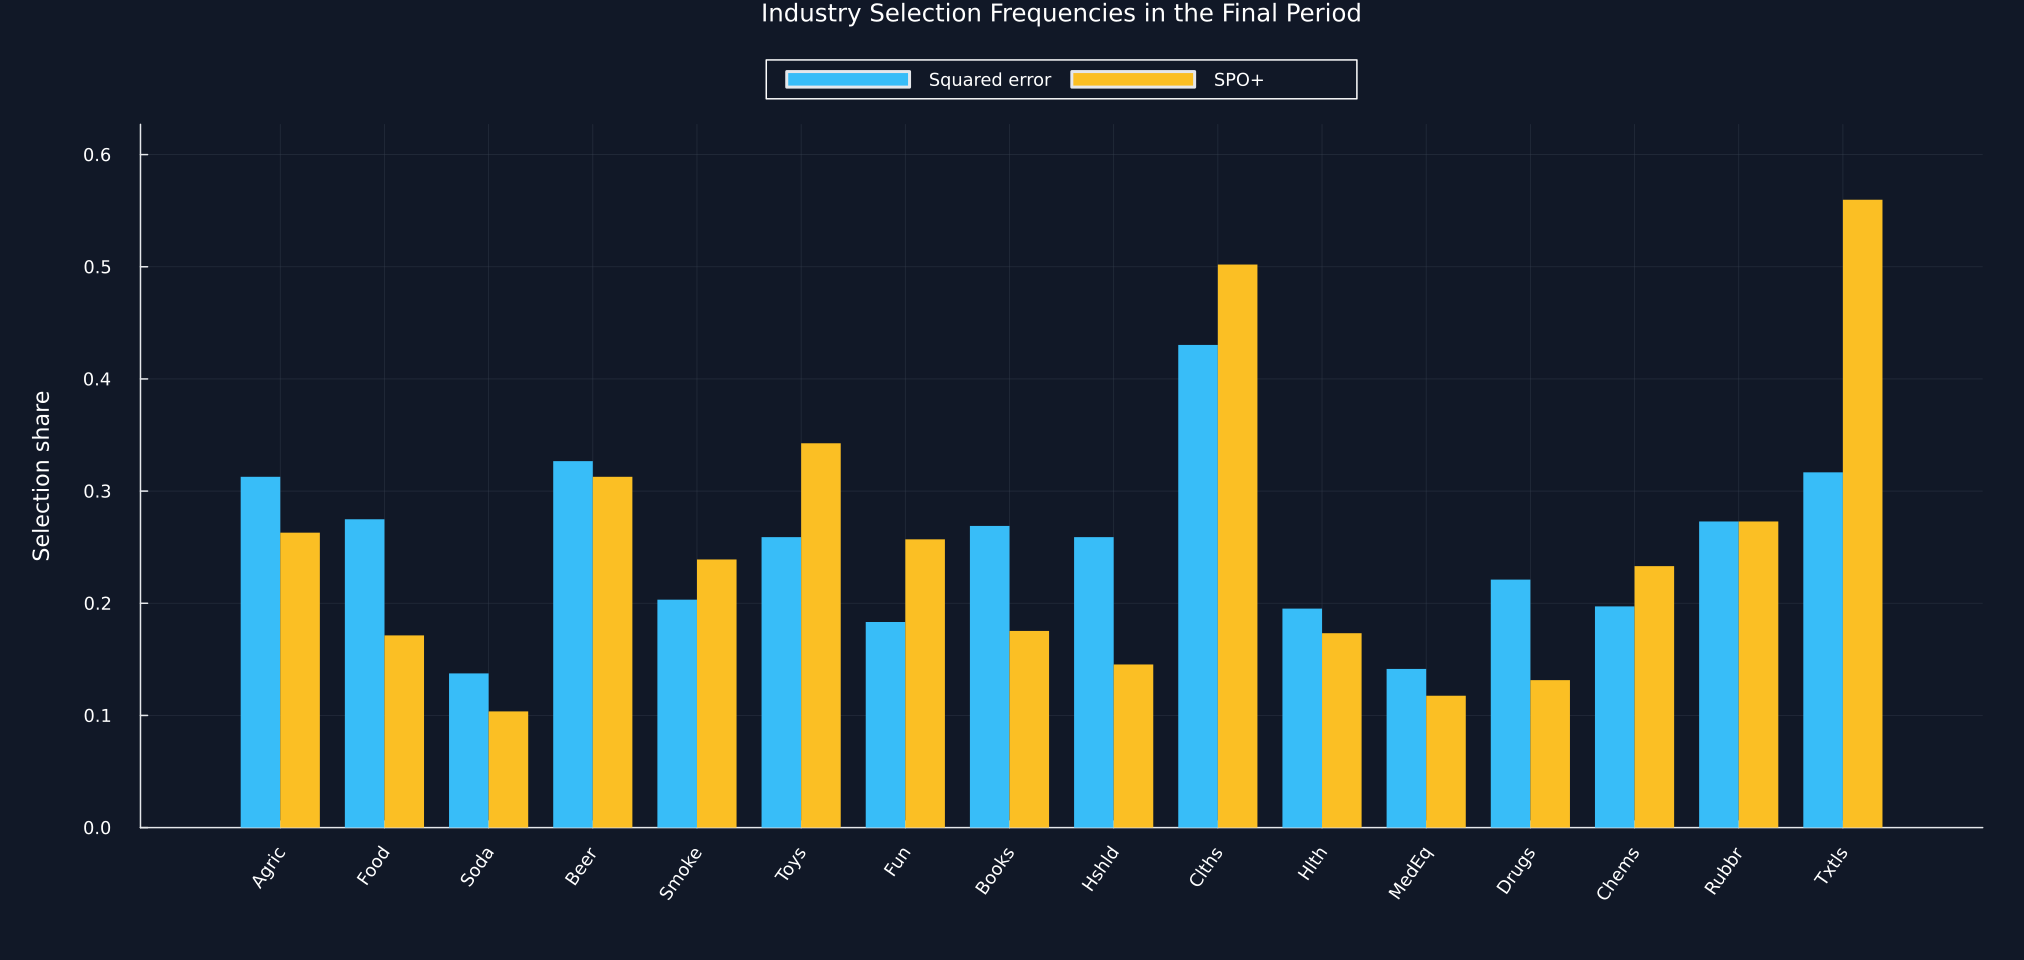

Row,Rule,Vertex,Industries,Selected dates
,String,Int64,String,Int64
1,Squared error,1537,"Toys, Books, Clths, Rubbr",11
2,Squared error,1587,"Toys, Clths, Chems, Rubbr",9
3,Squared error,300,"Agric, Toys, Books, Clths",7
4,Squared error,576,"Food, Beer, Hshld, Rubbr",6
5,Squared error,1589,"Toys, Clths, Rubbr, Txtls",6
6,SPO+,1588,"Toys, Clths, Chems, Txtls",17
7,SPO+,1589,"Toys, Clths, Rubbr, Txtls",12
8,SPO+,1579,"Toys, Clths, Hlth, Txtls",9
9,SPO+,1509,"Toys, Fun, Clths, Rubbr",8


Row,Question,Answered,Boundary
,String,String,String
1,Are all features based on earlier returns?,Pass,Direct timing checks
2,Are both rules the same size?,Pass,Seven shared coefficients each
3,Was the final test used to train or tune?,Fail,Untouched comparison
4,Does one split establish general superiority?,Fail,No general claim
5,Is the finite oracle a general solver?,Fail,Only supplied vertices


In [3]:
function evaluate_rule(beta,mask,name)
    prediction = predict_costs(study.design,beta)[mask,:]
    truth = study.costs[mask,:]
    predicted_index = argmin.(eachrow(prediction*vertices'))
    true_index = argmin.(eachrow(truth*vertices'))
    selected,optimal = vertices[predicted_index,:],vertices[true_index,:]
    selected_cost = vec(sum(truth.*selected;dims=2))
    optimal_cost = vec(sum(truth.*optimal;dims=2))
    regret = selected_cost-optimal_cost
    turnover = vcat(NaN,0.5vec(sum(abs.(diff(selected;dims=1));dims=2)))
    @assert minimum(regret)>=-1e-10
    return (;name,dates=dates[mask],prediction,truth,predicted_index,true_index,selected,selected_cost,optimal_cost,regret,turnover)
end
function metric_row(result,period)
    return (period=period,rule=result.name,mse=mean(abs2,result.prediction-result.truth),regret=mean(result.regret),cost=mean(result.selected_cost),best=mean(result.optimal_cost),exact=mean(result.predicted_index.==result.true_index),turnover=mean(filter(isfinite,result.turnover)))
end
metric_columns = ["Period","Rule","Mean squared error","Mean decision regret","Mean selected cost","Mean best vertex cost","Exact decision share","Mean turnover"]
validation_results = [evaluate_rule(beta_mse,validation_mask,"Squared error"),evaluate_rule(beta_spo,validation_mask,"SPO+")]
test_results = [evaluate_rule(beta_mse,test_mask,"Squared error"),evaluate_rule(beta_spo,test_mask,"SPO+")]
validation_metrics = rename!(DataFrame([metric_row(result,"Validation") for result in validation_results]),metric_columns)
test_metrics = rename!(DataFrame([metric_row(result,"Final test") for result in test_results]),metric_columns)
table(validation_metrics,"decision_validation_metrics","Fixed-rule diagnostics in the validation period.")
table(test_metrics,"decision_final_test_metrics","Untouched final-period diagnostics for the two fixed rules.")
benchmark = DataFrame("Decision"=>["Equal weight over sixteen industries","Squared error selected vertices","SPO+ selected vertices"],"Mean observed cost"=>[mean(study.costs[test_mask,:]),mean(test_results[1].selected_cost),mean(test_results[2].selected_cost)],"Mean turnover"=>[0.0,mean(filter(isfinite,test_results[1].turnover)),mean(filter(isfinite,test_results[2].turnover))],"Inside four-industry feasible set"=>[false,true,true])
table(benchmark,"decision_equal_weight_context","Equal weight is reported as an outside reference, not as a vertex-regret comparison.")
all_metrics = vcat(validation_metrics,test_metrics)
save_data(all_metrics,paths,"decision_metric_comparison")
panels = Any[]
for metric in ["Mean squared error","Mean decision regret"]
    figure = plot(;title=metric,xticks=(1:2,["Final test","Validation"]),legend=:outertop,legend_columns=2)
    for (offset,name,color) in [(-0.19,"SPO+",palette.cyan),(0.19,"Squared error",palette.amber)]
        values = [only(all_metrics[(all_metrics.Period.==period).&(all_metrics.Rule.==name),metric]) for period in ["Final test","Validation"]]
        bar!(figure,(1:2).+offset,values;bar_width=0.38,color,linealpha=0,label=name)
    end
    plot!(figure;ylims=(0,1.12maximum(all_metrics[!,metric])))
    push!(panels,figure)
end
save_figure(plot(panels...;layout=(1,2),size=(1300,540)),paths,"decision_metric_comparison")
cumulative_table = DataFrame([(Date=string(date),Rule=result.name,regret=value) for result in test_results for (date,value) in zip(result.dates,cumsum(result.regret))])
rename!(cumulative_table,:regret=>"Cumulative regret")
save_data(cumulative_table,paths,"decision_cumulative_regret")
ticks = Date.(2024:2026,1,1)
figure = plot(;title="Final Test Regret Accumulates Differently Across Fixed Rules",xlabel="Final test date",ylabel="Cumulative decision regret",legend=:outertop,legend_columns=2,xticks=(Dates.value.(ticks),string.(year.(ticks))),size=(1200,550))
for (result,color) in zip(test_results,[palette.cyan,palette.amber])
    plot!(figure,Dates.value.(result.dates),cumsum(result.regret);color,label=result.name,linewidth=2)
end
save_figure(figure,paths,"decision_cumulative_regret")
turnover_table = DataFrame([(Date=string(date),Rule=result.name,Turnover=value) for result in test_results for (date,value) in zip(result.dates,result.turnover) if isfinite(value)])
save_data(turnover_table,paths,"decision_turnover")
figure = plot(;title="Selected Decisions Change Through the Final Period",xlabel="Final test date",ylabel="Twenty-day mean turnover",legend=:outertop,legend_columns=2,xticks=(Dates.value.(ticks),string.(year.(ticks))),size=(1200,560))
for (result,color) in zip(test_results,[palette.cyan,palette.amber])
    values = result.turnover[2:end]
    rolling = [mean(values[max(1,i-19):i]) for i in eachindex(values)]
    plot!(figure,Dates.value.(result.dates[2:end]),rolling;color,label=result.name,linewidth=1.9)
end
save_figure(figure,paths,"decision_turnover")
frequency_table = DataFrame([(Industry=industries[i],Rule=result.name,share=mean(result.selected[:,i])*4) for result in test_results for i in 1:16])
rename!(frequency_table,:share=>"Selection share")
table(frequency_table,"decision_industry_selection_shares","Final-period share of dates on which each industry is selected.")
table(frequency_table[frequency_table.Rule.=="Squared error",:],"decision_industry_selection_shares_mse","Final-period industry selection shares for the squared-error rule.")
table(frequency_table[frequency_table.Rule.=="SPO+",:],"decision_industry_selection_shares_spo","Final-period industry selection shares for the SPO+ rule.")
save_data(frequency_table,paths,"decision_selection_frequencies")
figure = plot(;title="Industry Selection Frequencies in the Final Period",ylabel="Selection share",xticks=(1:16,industries),xrotation=55,legend=:outertop,legend_columns=2,ylims=(0,1.12maximum(frequency_table[!,"Selection share"])),size=(1350,640),bottom_margin=13Plots.mm)
for (offset,name,color) in [(-0.19,"Squared error",palette.cyan),(0.19,"SPO+",palette.amber)]
    bar!(figure,(1:16).+offset,frequency_table[frequency_table.Rule.==name,"Selection share"];bar_width=0.38,color,linealpha=0,label=name)
end
save_figure(figure,paths,"decision_selection_frequencies")
decision_rows = NamedTuple[]
for result in test_results
    encountered = unique(result.predicted_index)
    counts = [count(==(vertex),result.predicted_index) for vertex in encountered]
    positions = sortperm(counts;rev=true,alg=MergeSort)[1:5]
    for position in positions
        vertex = encountered[position]
        push!(decision_rows,(Rule=result.name,Vertex=vertex-1,Industries=join(industries[members[vertex]],", "),dates=counts[position]))
    end
end
decision_summary = rename!(DataFrame(decision_rows),:dates=>"Selected dates")
table(decision_summary,"decision_most_common_vertices","Five most common final-period vertices for each rule.")
limits = DataFrame("Question"=>["Are all features based on earlier returns?","Are both rules the same size?","Was the final test used to train or tune?","Does one split establish general superiority?","Is the finite oracle a general solver?"],"Answered"=>[true,true,false,false,false],"Boundary"=>["Direct timing checks","Seven shared coefficients each","Untouched comparison","No general claim","Only supplied vertices"])
table(limits,"decision_public_study_boundaries","Questions answered and not answered by the public decision study.")
save_data(DataFrame([(Rule=result.name,Period=period,Row=i,Selected=result.predicted_index[i]-1,Optimal=result.true_index[i]-1) for (period,results) in [("Validation",validation_results),("Final test",test_results)] for result in results for i in eachindex(result.predicted_index)]),paths,"native_evaluation_oracles")
nothing
